In [1]:
!pip -q install kagglehub

In [2]:
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: True


In [7]:
!pip -q install kagglehub

import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

SEED = 42
tf.keras.utils.set_random_seed(SEED)

dataset_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print("Dataset downloaded:", dataset_path)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset downloaded: /kaggle/input/intel-image-classification
GPU available: True


In [8]:
root = pathlib.Path(dataset_path)

expected_classes = {
    "buildings", "forest", "glacier",
    "mountain", "sea", "street"
}

def find_split_folder(split_name):
    for folder in root.rglob(split_name):
        if not folder.is_dir():
            continue

        child_dirs = {
            p.name.lower()
            for p in folder.iterdir()
            if p.is_dir()
        }

        if expected_classes.issubset(child_dirs):
            return folder

    raise FileNotFoundError(
        f"{split_name} not found. Dataset path: {root}"
    )

train_dir = find_split_folder("seg_train")
test_dir = find_split_folder("seg_test")

print("Training directory:", train_dir)
print("Testing directory:", test_dir)
print("Folders found successfully!")

Training directory: /kaggle/input/intel-image-classification/seg_train/seg_train
Testing directory: /kaggle/input/intel-image-classification/seg_test/seg_test
Folders found successfully!


In [9]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Classes:", class_names)
print("Total classes:", NUM_CLASSES)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Total classes: 6


In [10]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("All datasets are ready.")

All datasets are ready.


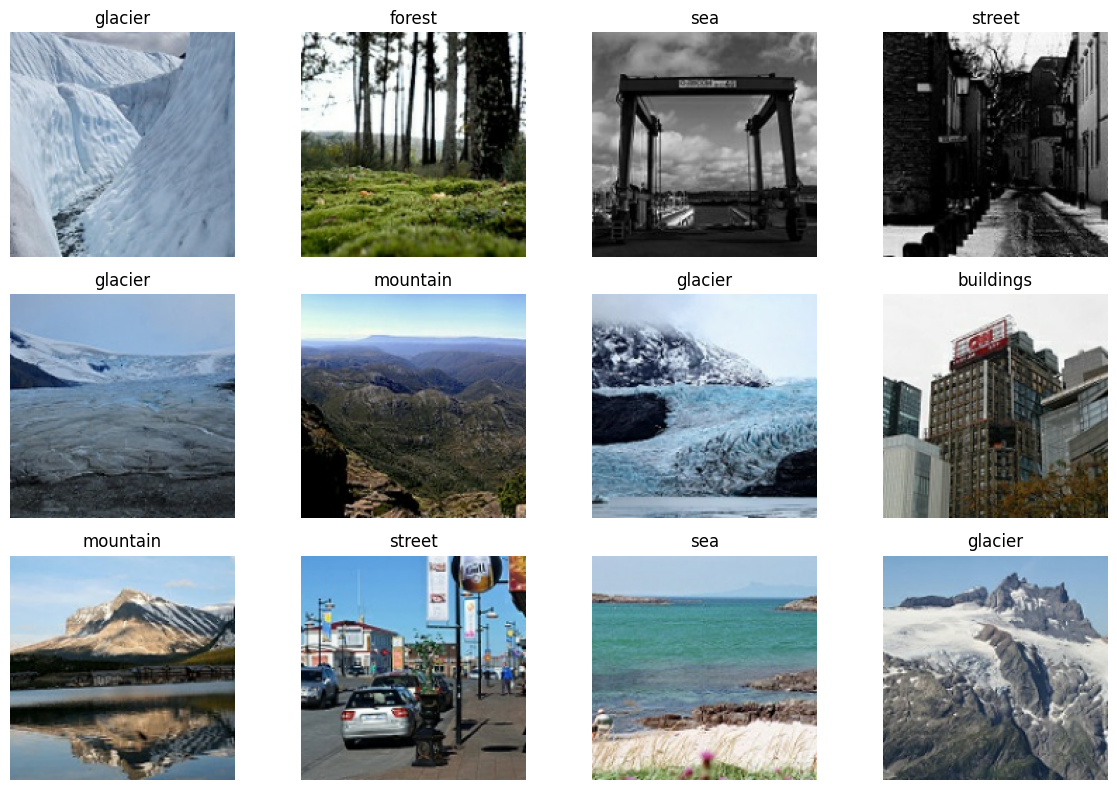

In [11]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
])

base_model = MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(160, 160, 3))

x = data_augmentation(inputs)
x = layers.Lambda(preprocess_input)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_intel_cnn.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

print("Initial CNN training completed.")

Epoch 1/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.6874 - loss: 0.8178
Epoch 1: val_accuracy improved from None to 0.88917, saving model to /content/best_intel_cnn.keras

Epoch 1: finished saving model to /content/best_intel_cnn.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 53s 123ms/step - accuracy: 0.7961 - loss: 0.5419 - val_accuracy: 0.8892 - val_loss: 0.2842 - learning_rate: 0.0010
Epoch 2/8
350/351 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8650 - loss: 0.3702
Epoch 2: val_accuracy improved from 0.88917 to 0.90449, saving model to /content/best_intel_cnn.keras

Epoch 2: finished saving model to /content/best_intel_cnn.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.8687 - loss: 0.3570 - val_accuracy: 0.9045 - val_loss: 0.2561 - learning_rate: 0.0010
Epoch 3/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8831 - loss: 0.3295
Epoch 3: val_accuracy did not improve from 0.90449
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - accuracy: 0.8840 - loss: 0.3

In [14]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=7,
    callbacks=callbacks
)

print("Fine-tuning completed.")

Epoch 1/7
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8959 - loss: 0.2792
Epoch 1: val_accuracy improved from 0.91304 to 0.91768, saving model to /content/best_intel_cnn.keras

Epoch 1: finished saving model to /content/best_intel_cnn.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 26s 54ms/step - accuracy: 0.8972 - loss: 0.2748 - val_accuracy: 0.9177 - val_loss: 0.2189 - learning_rate: 1.0000e-05
Epoch 2/7
350/351 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9068 - loss: 0.2528
Epoch 2: val_accuracy improved from 0.91768 to 0.92195, saving model to /content/best_intel_cnn.keras

Epoch 2: finished saving model to /content/best_intel_cnn.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - accuracy: 0.9066 - loss: 0.2521 - val_accuracy: 0.9220 - val_loss: 0.2097 - learning_rate: 1.0000e-05
Epoch 3/7
350/351 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9138 - loss: 0.2297
Epoch 3: val_accuracy improved from 0.92195 to 0.92302, saving model to /content/best_intel_cnn.keras

Epoch 3: fi

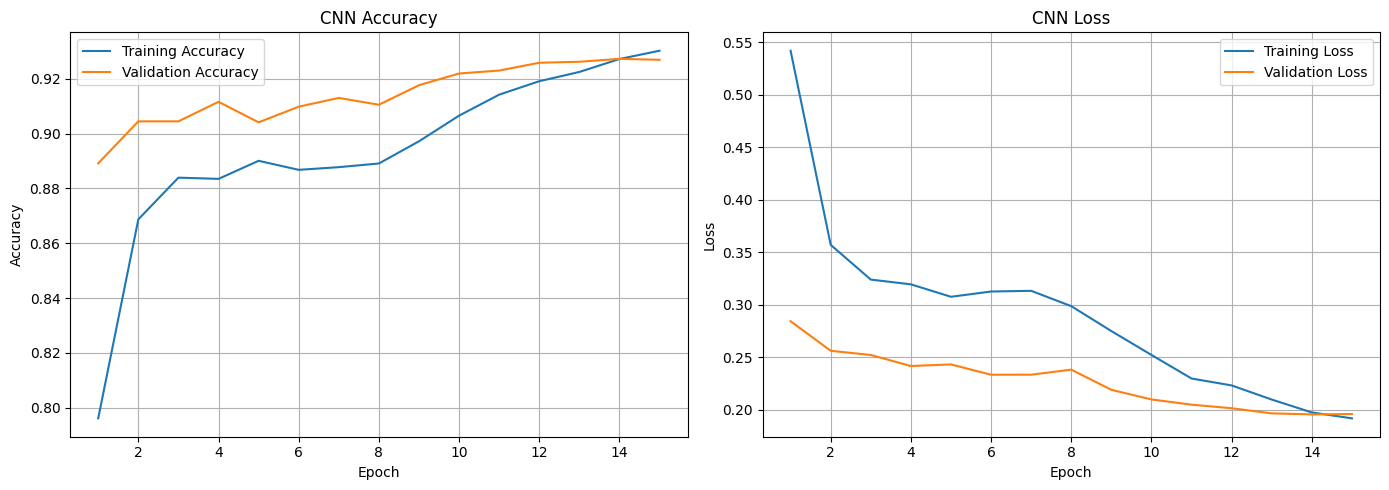

In [15]:
train_accuracy = history1.history["accuracy"] + history2.history["accuracy"]
val_accuracy = history1.history["val_accuracy"] + history2.history["val_accuracy"]

train_loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("/content/intel_cnn_accuracy_loss.png", dpi=300)
plt.show()

In [19]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

best_model = tf.keras.models.load_model(
    "/content/best_intel_cnn.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

best_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("=" * 45)
print("INTEL CNN TEST RESULTS")
print("=" * 45)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - accuracy: 0.9240 - loss: 0.2062
INTEL CNN TEST RESULTS
Test Accuracy: 92.40%
Test Loss: 0.2062


94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step


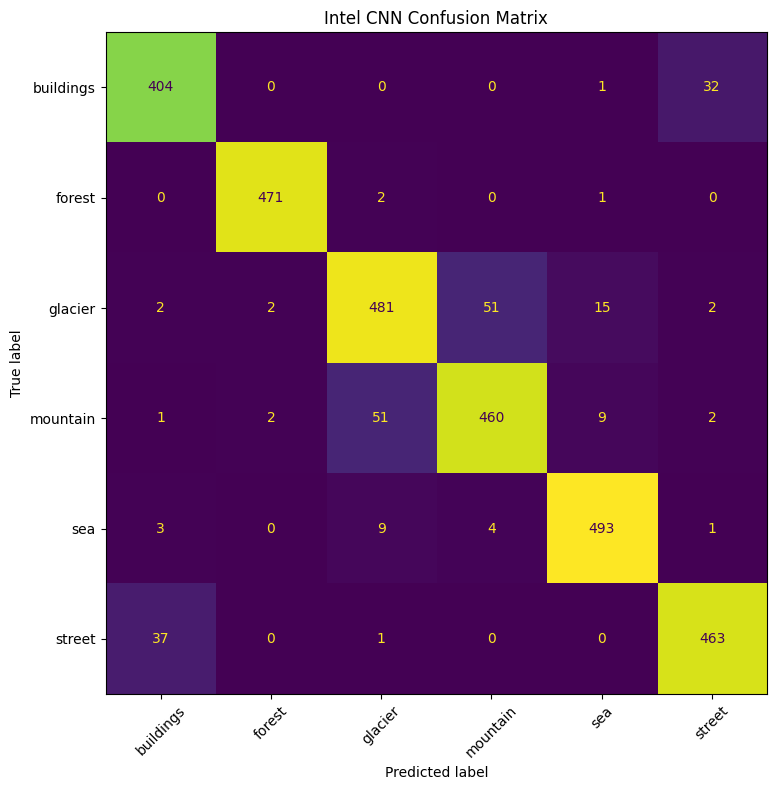


Classification Report:

              precision    recall  f1-score   support

   buildings       0.90      0.92      0.91       437
      forest       0.99      0.99      0.99       474
     glacier       0.88      0.87      0.88       553
    mountain       0.89      0.88      0.88       525
         sea       0.95      0.97      0.96       510
      street       0.93      0.92      0.93       501

    accuracy                           0.92      3000
   macro avg       0.92      0.93      0.93      3000
weighted avg       0.92      0.92      0.92      3000



In [20]:
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(10, 8))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display_cm.plot(
    ax=ax,
    xticks_rotation=45,
    colorbar=False
)

plt.title("Intel CNN Confusion Matrix")
plt.tight_layout()
plt.savefig("/content/intel_cnn_confusion_matrix.png", dpi=300)
plt.show()

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))

In [21]:
results = pd.DataFrame({
    "Actual": [class_names[i] for i in y_true],
    "Predicted": [class_names[i] for i in y_pred],
    "Confidence_Percent": np.max(y_prob, axis=1) * 100,
    "Correct": y_true == y_pred
})

results.to_csv(
    "/content/intel_cnn_predictions.csv",
    index=False
)

print("Actual vs Predicted:")
print(results.head(20).to_string(index=False))

print("\nCorrect predictions:", int(results["Correct"].sum()))
print("Incorrect predictions:", int((~results["Correct"]).sum()))
print("CSV saved: /content/intel_cnn_predictions.csv")

Actual vs Predicted:
   Actual Predicted  Confidence_Percent  Correct
buildings buildings           99.996590     True
buildings buildings           98.749252     True
buildings buildings           99.794907     True
buildings buildings           99.923531     True
buildings buildings           99.953140     True
buildings buildings           85.473137     True
buildings buildings           99.979668     True
buildings    street           57.986526    False
buildings buildings           92.389229     True
buildings buildings           99.890923     True
buildings buildings           98.748734     True
buildings buildings           99.205956     True
buildings buildings           99.972229     True
buildings buildings           96.031830     True
buildings buildings           99.996857     True
buildings buildings           97.575607     True
buildings buildings           99.818085     True
buildings buildings           99.699875     True
buildings buildings           99.767372     True

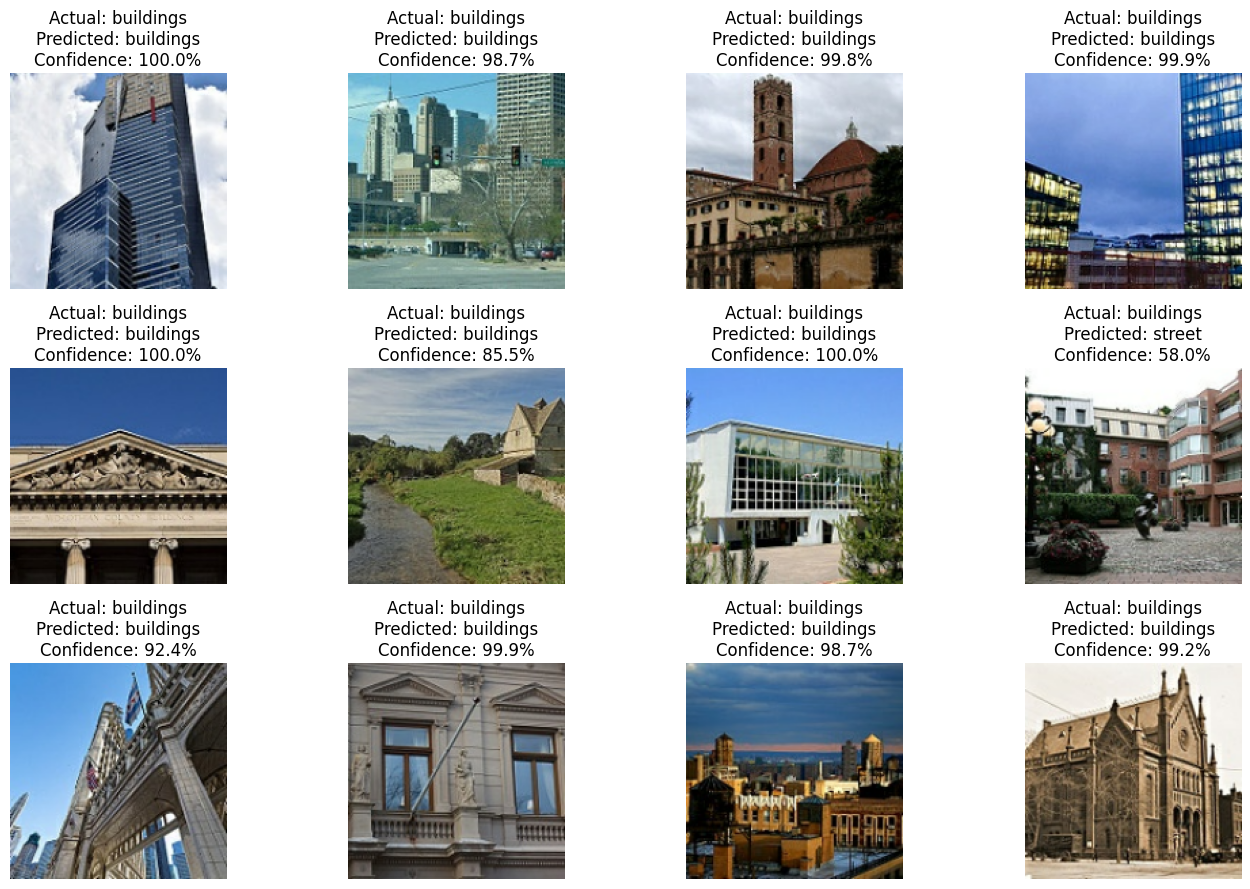

In [23]:
plt.figure(figsize=(14, 9))

for images, labels in test_ds.take(1):
    images_np = images.numpy()
    labels_np = labels.numpy()

    predictions = best_model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    for i in range(min(12, len(images_np))):
        plt.subplot(3, 4, i + 1)

        plt.imshow(images_np[i].astype("uint8"))

        actual = class_names[int(labels_np[i])]
        predicted = class_names[int(predicted_labels[i])]
        confidence = float(np.max(predictions[i])) * 100

        plt.title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Confidence: {confidence:.1f}%"
        )

        plt.axis("off")

plt.tight_layout()
plt.savefig("/content/intel_cnn_sample_predictions.png", dpi=300)
plt.show()

In [24]:
best_model.save(
    "/content/intel_image_classification_cnn.keras"
)

print("PROJECT FILES SAVED")
print("-" * 45)

files = [
    "/content/intel_image_classification_cnn.keras",
    "/content/intel_cnn_accuracy_loss.png",
    "/content/intel_cnn_confusion_matrix.png",
    "/content/intel_cnn_predictions.csv",
    "/content/intel_cnn_sample_predictions.png"
]

for file_path in files:
    if os.path.exists(file_path):
        print("Available:", file_path)
    else:
        print("Not found:", file_path)

PROJECT FILES SAVED
---------------------------------------------
Available: /content/intel_image_classification_cnn.keras
Available: /content/intel_cnn_accuracy_loss.png
Available: /content/intel_cnn_confusion_matrix.png
Available: /content/intel_cnn_predictions.csv
Available: /content/intel_cnn_sample_predictions.png


In [25]:
print("=" * 55)
print("INTEL IMAGE CLASSIFICATION CNN PROJECT")
print("=" * 55)

print("Dataset       : Intel Image Classification (Kaggle)")
print("Model         : MobileNetV2 Transfer Learning CNN")
print("Image Size    : 160 x 160")
print("Classes       :", ", ".join(class_names))
print("Total Classes :", NUM_CLASSES)
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

print("\nClassification metrics:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))

print("Model         : intel_image_classification_cnn.keras")
print("Predictions   : intel_cnn_predictions.csv")
print("Graphs        : Accuracy/Loss and Confusion Matrix")

print("=" * 55)
print("CNN PROJECT COMPLETED SUCCESSFULLY")
print("=" * 55)

INTEL IMAGE CLASSIFICATION CNN PROJECT
Dataset       : Intel Image Classification (Kaggle)
Model         : MobileNetV2 Transfer Learning CNN
Image Size    : 160 x 160
Classes       : buildings, forest, glacier, mountain, sea, street
Total Classes : 6
Test Accuracy : 92.40%
Test Loss     : 0.2062

Classification metrics:
              precision    recall  f1-score   support

   buildings       0.90      0.92      0.91       437
      forest       0.99      0.99      0.99       474
     glacier       0.88      0.87      0.88       553
    mountain       0.89      0.88      0.88       525
         sea       0.95      0.97      0.96       510
      street       0.93      0.92      0.93       501

    accuracy                           0.92      3000
   macro avg       0.92      0.93      0.93      3000
weighted avg       0.92      0.92      0.92      3000

Model         : intel_image_classification_cnn.keras
Predictions   : intel_cnn_predictions.csv
Graphs        : Accuracy/Loss and Confus